#### Improving makemore_2.ipynb


In [18]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [19]:
# read in all the words
words = open("names.txt", "r").read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [20]:
len(words)

32033

In [21]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set("".join(words))))
stoi = {s: i + 1 for i, s in enumerate(chars)}  # stoi: string to integer
stoi["."] = 0  # add a special token to represent the start/end of a word
itos = {i: s for s, i in stoi.items()}  # itos: integer to string

In [247]:
block_size = (
    10  # context length: how many characters do we take to predict the next one?
)
embedding_dim = 10  # embedding dimension: the number of features in the character vector representation
batch_size = 128  # how many independent sequences will we process in parallel?

In [248]:
# build the dataset


def build_dataset(words):

    X, Y = [], []
    for w in words:
        # print(w)
        context = [
            0
        ] * block_size  # initialize the context with all start-of-word tokens
        for ch in w + ".":
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print("".join(itos[i] for i in context), "----->", itos[ix])
            context = context[1:] + [ix]  # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y


import random

random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))
Xtr, Ytr = build_dataset(words[:n1])  # first 80%
Xdev, Ydev = build_dataset(words[n1:n2])  # middle 10%
Xte, Yte = build_dataset(words[n2:])  # last 10%

torch.Size([182424, 10]) torch.Size([182424])
torch.Size([22836, 10]) torch.Size([22836])
torch.Size([22886, 10]) torch.Size([22886])


In [249]:
Xtr.shape, Ytr.shape  # training dataset

(torch.Size([182424, 10]), torch.Size([182424]))

In [250]:
g = torch.Generator().manual_seed(2147483647)  # for reproducibility
C = torch.randn((27, embedding_dim), generator=g)
W1 = torch.randn((block_size * embedding_dim, 200), generator=g)
b1 = torch.randn(200, generator=g)  # 200 outputs
W2 = torch.randn((200, 27), generator=g)  # 200 inputs, 27 outputs
b2 = torch.randn(27, generator=g)  # 27 outputs
parameters = [C, W1, b1, W2, b2]

In [251]:
sum(p.nelement() for p in parameters)  # number of parameters in the model

25897

In [252]:
for p in parameters:
    p.requires_grad = (
        True  # make sure we can compute gradients with respect to these variables
    )

In [200]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [201]:
lri = []
lossi = []
stepi = []

In [260]:
for i in range(200000):
    # minibatch construct
    ix = torch.randint(
        0, Xtr.shape[0], (batch_size,)
    )  # sample 32 random integers from 0 to the number of examples

    # forwards pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, block_size * embedding_dim) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])

    # print(loss.item())

    # backwards pass
    for p in parameters:
        p.grad = None  # set the gradient to zero before running the backward pass
    loss.backward()

    # update
    # lr = lrs[i]
    lr = 0.1 if i < 100000 else 0.01  # learning rate decay
    for p in parameters:
        p.data += -lr * p.grad  # gradient descent

    # track stats
    # lri.append(lre[i])
    stepi.append(i)
    lossi.append(loss.log10().item())

print(loss.item())

2.1418521404266357


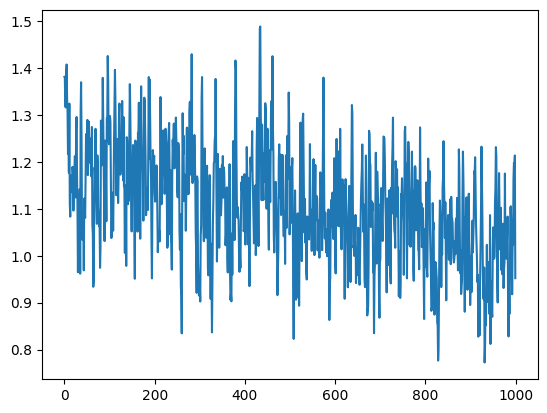

In [203]:
plt.plot(stepi, lossi)

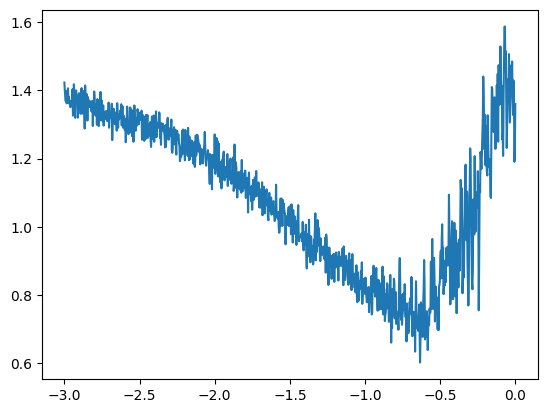

In [196]:
plt.plot(lri, lossi)

In [261]:
emb = C[Xtr]
h = torch.tanh(emb.view(-1, block_size * embedding_dim) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.1928, grad_fn=<NllLossBackward0>)

In [262]:
emb = C[Xdev]
h = torch.tanh(emb.view(-1, block_size * embedding_dim) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.2290, grad_fn=<NllLossBackward0>)

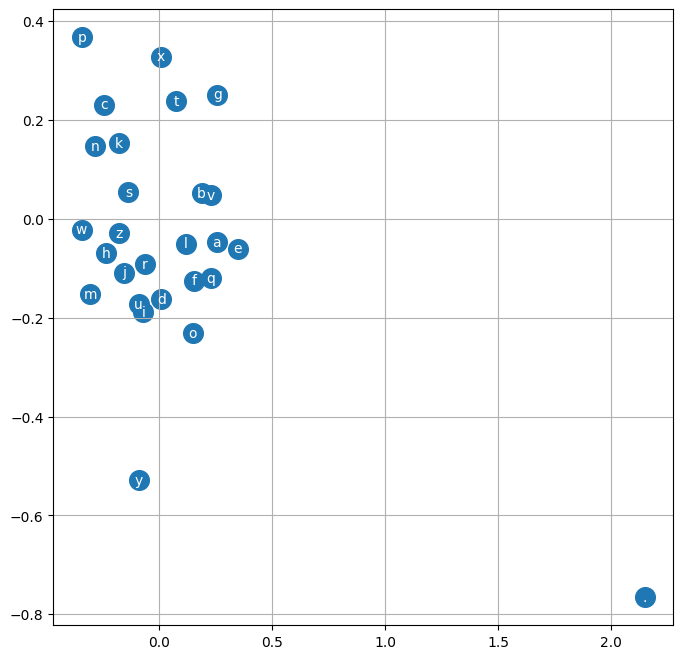

In [263]:
plt.figure(figsize=(8, 8))
plt.scatter(C[:, 0].data, C[:, 1].data, s=200)
for i in range(C.shape[0]):
    plt.text(
        C[i, 0].item(), C[i, 1].item(), itos[i], ha="center", va="center", color="white"
    )
plt.grid("minor")

In [264]:
# sample for the model
g = torch.Generator().manual_seed(2147483647 + embedding_dim)  # for reproducibility

for _ in range(20):
    out = []
    context = [0] * block_size  # initialize the context with all start-of-word tokens
    while True:
        emb = C[torch.tensor([context])]  # (1, block_size, d)
        h = torch.tanh(emb.view(-1, block_size * embedding_dim) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]  # crop and append
        out.append(ix)
        if ix == 0:
            break

    print("".join(itos[i] for i in out))

carlah.
amille.
khiimli.
reety.
skanden.
jazhnel.
deliya.
jareei.
nelenia.
chaiia.
kaleigh.
hamon.
cadesinn.
shoilea.
jadbi.
wazelon.
jaryni.
jamek.
dusan.
eddeco.
